In [1]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from importlib import reload
from model.loss import LatentPairwiseContrastiveLoss, LatentPairwiseContrastiveSAELoss, SupervisedInfoNCELoss

## Contrastive Training

### Simulated data

In [2]:
def extract_embeddings_basic_ae(model, data_loader, device):
    model.eval()
    embeddings = []
    labels = []
    with torch.no_grad():
        for X_batch, y_batch in data_loader:
            X_batch = X_batch.to(device)
            #X_batch = F.normalize(X_batch, p=2, dim=1)
            emb = model.encoder(X_batch)
            embeddings.append(emb)
            labels.append(y_batch)
    return torch.vstack(embeddings), torch.concatenate(labels, axis=0)

def extract_basic_embeddings_transformer(model, data_loader, device):
    model.eval()
    embeddings = []
    labels = []
    with torch.no_grad():
        for X_batch, y_batch in data_loader:
            X_batch = X_batch.to(device)
            #X_batch = F.normalize(X_batch, p=2, dim=1)
            emb = model(X_batch)
            embeddings.append(emb)
            labels.append(y_batch)
    return torch.vstack(embeddings), torch.concatenate(labels, axis=0)

In [3]:
from experiments.synthetic_datasets import setup_synthetic_dataloaders, generate_synthetic_data

n_train_samples = 200
input_dim = 128
n_calib_samples = 40
batch_size = 32

train_set, calib_set, val_set = generate_synthetic_data(input_dim, n_train_samples, n_calib_samples)
contrastive_train_loader_syn,train_loader_syn,calib_loader_syn,val_loader_syn = setup_synthetic_dataloaders(train_set, calib_set, val_set, batch_size)



Train/Calib/Test Sizes: 140 / 40 / 20


In [5]:
from model.models import ContrastiveClusterLearner


def conformal_prediction_with_basic_ae_synthetic_data(ae_model, embed_transformer_service, train_loader, calib_loader, val_loader):
    latent_dim = 16
    #embedding_dim = 4
    
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    # Clustering model
    ccl_model = ContrastiveClusterLearner(embed_transformer=embed_transformer_service, device=device)
    
    # 1. Extract L2-Normalized Embeddings from the Autoencoder
    train_emb, train_labels_extracted = extract_embeddings_basic_ae(ae_model, train_loader, device)
    calib_emb, calib_labels_extracted = extract_embeddings_basic_ae(ae_model, calib_loader, device)
    val_emb, val_labels = extract_embeddings_basic_ae(ae_model, val_loader, device)

    combined_emb = torch.vstack((train_emb, calib_emb, val_emb))
    combined_labels = torch.concatenate((train_labels_extracted, calib_labels_extracted, val_labels), axis=0)

    #combined_emb_proj = ae_model.encoder(combined_emb).detach()
    
    len_train_data = train_emb.shape[0]
    len_calib_data = calib_emb.shape[0]
    len_val_data = val_emb.shape[0]
    assert(len_train_data+len_calib_data+len_val_data == combined_emb.shape[0])
    
    # Compute LOO Non-Conformity Scores (Alpha Values) for Calibration Set
    # This calculation ensures no 0 distance scores are included.
    calib_alphas = ccl_model.calculate_calibration_conformity_scores_loo(calib_emb, calib_labels_extracted)

    # Calculate Quantile q_hat with Monte Carlo (Bootstrap) Sampling
    CONFIDENCE_LEVEL = 0.9
    n_bootstrap_samples = 500
    q_hat = ccl_model.critical_quantile_mc(calib_alphas, confidence_level=CONFIDENCE_LEVEL, n_bootstrap_samples=n_bootstrap_samples)
    print(f"q_hat values: {q_hat}")

    # Compute Test Set Non-Conformity Scores
    # Distance from test point to the nearest calibration point in each class.
    all_test_scores = ccl_model.calculate_test_conformity_scores(calib_emb, calib_labels_extracted, val_emb)
    #print(all_test_scores)
    #print(test_labels)

    # 5. Determine Prediction Sets
    prediction_sets, coverage_count, conditional_coverage_total, conditional_coverage_correct = ccl_model.compute_conditional_coverage(q_hat, all_test_scores, val_labels)
    
    # --- 3.4. Evaluation ---
    total_sets = len(prediction_sets)
    coverage = coverage_count / total_sets
    avg_set_size = np.mean([len(s) for s in prediction_sets])
    set_sizes = [len(s) for s in prediction_sets]
    
    print("\n--- Conformal Prediction Results ---")
    print(f"Target Confidence (1-alpha): {CONFIDENCE_LEVEL:.2f}")
    print(f"Empirical Marginal Coverage: {coverage:.4f}")
    print(f"Average Prediction Set Size: {avg_set_size:.3f}")

    counts = {}
    for item in set_sizes:
        counts[item] = counts.get(item, 0) + 1
    print(f"Prediction Set Sizes Per Class: {counts}")
    print(f"Proportion of Set Size 1: {counts[1]/sum(counts.values())}")
    
    print("\n--- Empirical Conditional Coverage ---")
    # This shows the actual coverage achieved for each specific class
    for c in sorted(conditional_coverage_total.keys()):
        total = conditional_coverage_total[c]
        correct = conditional_coverage_correct[c]
        if total > 0:
            cond_cov = correct / total
            print(f"  Class {c} Coverage (n={total}): {cond_cov:.4f}")
        else:
            print(f"  Class {c} Coverage (n=0): N/A (No test samples for this class)")
    
    # Example visualization of the first 5 predictions
    print("\nValidation Predictions (True Label | Prediction Set):")
    for i in range(5):
        print(f"  {val_labels[i]} | {prediction_sets[i]}")

    return ccl_model, prediction_sets, train_emb, calib_emb, val_emb


In [ ]:
from experiments.synthetic_training import train_autoencoder_e2_synthetic_data, train_contrastive_embeddings_transformer_with_synthetic_data

# MLP Projectord
input_dim = 128
latent_dim = 32
device = torch.device("cuda" if torch.cuda.is_available() else "cpu") 
epochs=40
emb_model = train_contrastive_embeddings_transformer_with_synthetic_data(contrastive_train_loader_syn, input_dim=input_dim, 
                                                           latent_dim=latent_dim, device=device, epochs=epochs)

In [ ]:
# Train simple autoencoder
input_dim = 128
latent_dim = 32
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
epochs = 5
ae_basic_model = \
    train_autoencoder_e2_synthetic_data(train_loader=train_loader_syn,embed_transformer=emb_model, input_dim=input_dim, latent_dim=latent_dim, device=device, epochs=epochs)

In [ ]:
ccl_model, prediction_sets, train_emb, calib_emb, val_emb = \
    conformal_prediction_with_basic_ae_synthetic_data(ae_basic_model, emb_model, train_loader_syn, 
                                                      calib_loader_syn, val_loader_syn)


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
embeddings_train_syn,labels_train_syn = extract_basic_embeddings_transformer(emb_model, train_loader_syn, device)
print(f"Train data size: {embeddings_train_syn.shape}")
embeddings_val_syn,labels_val_syn = extract_basic_embeddings_transformer(emb_model, val_loader_syn, device)
print(f"Validation data size: {embeddings_val_syn.shape}")
embeddings_calib_syn,labels_calib_syn = extract_basic_embeddings_transformer(emb_model, calib_loader_syn, device)
print(f"Calibration data size: {embeddings_calib_syn.shape}")

embeddings_syn = torch.vstack((embeddings_train_syn,embeddings_val_syn,embeddings_calib_syn))
labels_syn = torch.concat((labels_train_syn,labels_val_syn,labels_calib_syn)).tolist()


In [ ]:
from model.training import majority_vote_relabeling

#### Clustering

# Find clusters
K=2
clusters_train_syn, centroids_train_syn = ccl_model.cosine_kmeans(embeddings_train_syn, K)
clusters_train_syn = clusters_train_syn.detach().cpu().numpy()
clusters_train_syn, clusters_labels_mapping = majority_vote_relabeling(y_true=labels_train_syn, y_pred=clusters_train_syn)

# Predict centers
clusters_val_syn = ccl_model.predict_clusters(embeddings_val_syn, centroids_train_syn).detach().cpu().numpy()
clusters_val_syn = np.vectorize(clusters_labels_mapping.get)(clusters_val_syn)

clusters_calib_syn = ccl_model.predict_clusters(embeddings_calib_syn, centroids_train_syn).detach().cpu().numpy()
clusters_calib_syn = np.vectorize(clusters_labels_mapping.get)(clusters_calib_syn)

clusters_syn = np.concat((clusters_train_syn, clusters_val_syn, clusters_calib_syn))

print(f"Number of assigned cluster centroids: {len(clusters_syn)}")
print(f"Number of assigned calibration cluster centroids: {len(clusters_calib_syn)}")


In [101]:
from sklearn.manifold import TSNE


tsne = TSNE(n_components=2, random_state=42, perplexity=10)
orig_train_tsne = tsne.fit_transform(train_set[0])



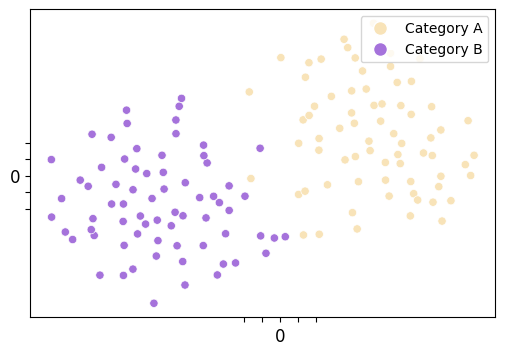

In [102]:
## Plot original data

import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# Flip if needed to shown category A above category B
#orig_train_tsne[:, 1] = orig_train_tsne[:, 1] * -1

plt.figure(figsize=(6,4))
plt.rcParams.update({'font.size': 12})
ax = sns.scatterplot(
    x=orig_train_tsne[:, 0],
    y=orig_train_tsne[:, 1],
    hue=labels_train_syn,
    palette=["#f8e3b8","#a572db"],
)

plt.xlabel("")
plt.ylabel("")
ax.set_xticks([-4, -2, 0, 2, 4])
ax.set_yticks(range(-4,5,2))
ax.set_xticklabels(['','',0,'',''])
ax.set_yticklabels(['','',0,'',''])
plt.grid(False)

handles, _ = ax.get_legend_handles_labels()
# Add the legend with custom labels
patch_a = Line2D([0], [0], marker='o', color='white', markerfacecolor="#f8e3b8", markersize=10, label='Category A')
patch_b = Line2D([0], [0], marker='o', color='white', markerfacecolor="#a572db", markersize=10, label='Category B')
ax.legend(handles=[patch_a, patch_b],loc='upper right', fontsize=10)

#plt.savefig("simulated_embeds.pdf", format="pdf", bbox_inches='tight', dpi=300)
#plt.savefig("simulated_embeds_sae.pdf", format="pdf", bbox_inches='tight')
plt.show()


In [65]:
from sklearn.manifold import TSNE


tsne = TSNE(n_components=2, random_state=42)
orig_train_val_calib_emb_tsne = tsne.fit_transform(embeddings_syn.detach().cpu().numpy())

len_train_data = embeddings_train_syn.shape[0]
len_val_data = embeddings_val_syn.shape[0]
len_calib_data = embeddings_calib_syn.shape[0]

orig_train_emb_tsne = orig_train_val_calib_emb_tsne[:len_train_data,:]
orig_train_labels = labels_syn[:len_train_data]
orig_train_val_emb_tsne = orig_train_val_calib_emb_tsne[:len_train_data+len_val_data,:]
orig_train_val_labels = labels_syn[:len_train_data+len_val_data]

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


plt.figure(figsize=(6,4))
plt.rcParams.update({'font.size': 12})
ax = sns.scatterplot(
    x=orig_train_emb_tsne[:, 0],
    y=orig_train_emb_tsne[:, 1],
    c=["#dbb2bf"],
)

plt.xlabel("")
plt.ylabel("")
ax.set_xticks([-10, -5, 0, 5, 10])
ax.set_yticks([-10, -5, 0, 5, 10])
ax.set_xticklabels(['','',0,'',''])
ax.set_yticklabels(['','',0,'',''])
plt.grid(False)

handles, _ = ax.get_legend_handles_labels()
# Add the legend with custom labels
orange_patch = Line2D([0], [0], marker='o', color='white', markerfacecolor="#dbb2bf", markersize=10, label='Manifold (TSNE)')
ax.legend(handles=[orange_patch],loc='upper right', fontsize=10)

#plt.savefig("simulated_embeds_tsne.pdf", format="pdf", bbox_inches='tight', dpi=300)
#plt.savefig("simulated_embeds_tsne_sae.pdf", format="pdf", bbox_inches='tight')
plt.show()

In [ ]:
embeddings_train_syn_tsne = orig_train_val_calib_emb_tsne[:len_train_data, :]
embeddings_val_syn_tsne = orig_train_val_calib_emb_tsne[len_train_data:len_train_data+len_val_data, :]
embeddings_calib_syn_tsne = orig_train_val_calib_emb_tsne[-len_calib_data:, :]


In [ ]:
# Find miscategorized points

mis_indices = []
#swap_clusters_syn = 1 - clusters_train_syn
swap_clusters_syn = clusters_train_syn
for i,c in enumerate(swap_clusters_syn):
    if c != labels_train_syn[i]:
        mis_indices.append(i)

print(f"Number of points miscategorized: {len(mis_indices)}")

unique set sizes: [0 1 2]


/tmp/ipykernel_37/1563367857.py:63: UserWarning: The palette list has more values (2) than needed (1), which may not be intended.
  sns.scatterplot(


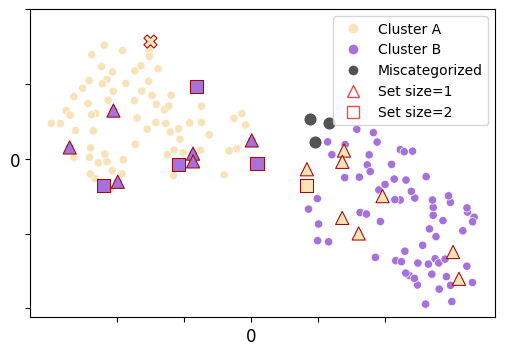

In [68]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


plt.figure(figsize=(6,4))
plt.rcParams.update({'font.size': 12})
ax = sns.scatterplot(
    x=embeddings_train_syn_tsne[:, 0],
    y=embeddings_train_syn_tsne[:, 1],
    hue=clusters_train_syn,
    palette=["#f8e3b8","#a572db"],
)

marker_mapping = {0: "o",1: "o"}
sns.scatterplot(
    x=embeddings_val_syn_tsne[:, 0],
    y=embeddings_val_syn_tsne[:, 1],
    hue=clusters_val_syn,
    palette=["#f8e3b8","#a572db"],
    markers=marker_mapping,
    ax=ax,
    style=labels_val_syn,
    #edgecolor="#2e2c2c",
)

# Highlight miscategorized points
for j in mis_indices:
    sns.scatterplot(
        x=[orig_train_emb_tsne[j, 0]],
        y=[orig_train_emb_tsne[j, 1]], 
        c=["#515450"],
        ax=ax,
        s=90
    )

avg_set_size = np.mean([len(s) for s in prediction_sets])
prediction_set_sizes = [len(s) for s in prediction_sets]
unique_sizes = np.sort(np.unique(prediction_set_sizes))

# Plot each data point    
print(f"unique set sizes: {unique_sizes}")
for set_idx, size in enumerate(unique_sizes):
    mask = (prediction_set_sizes == size)
    
    # Use different marker shapes based on the true label for context
    marker_map = {0: 'X', 1: '^', 2: 's'}

    # Ensure there are points to plot for the current size
    if np.sum(mask) == 0:
        continue
        
    # Determine the marker type for the points in this group
    # This assumes that the labels within a cluster are homogenous
    #current_labels = test_labels_2d[mask]
    current_labels = clusters_val_syn[mask]
    #marker_type = marker_map.get(np.sort(current_labels)[::-1][0], 'o') 
    marker_type = marker_map[size]
    
    # Plotting the points corresponding to the current set size
    sns.scatterplot(
        x=embeddings_val_syn_tsne[mask, 0],
        y=embeddings_val_syn_tsne[mask, 1], 
        hue=current_labels,
        palette=["#f8e3b8","#a572db"],
        marker=marker_type,
        ax=ax,
        s=90,
        edgecolors='#a60707'  # Highlight points with large sets
    )

plt.xlabel("")
plt.ylabel("")
ax.set_xticks(range(-10,15,5))
ax.set_yticks(range(-10,15,5))
ax.set_xticklabels(['','',0,'',''])
ax.set_yticklabels(['','',0,'',''])
handles, _ = ax.get_legend_handles_labels()
# Add the legend with custom labels
cata_patch = Line2D([0], [0], marker='o', color='white', markerfacecolor="#f8e3b8", markersize=8, label='Cluster A')
catb_patch = Line2D([0], [0], marker='o', color='white', markerfacecolor="#a572db", markersize=8, label='Cluster B')
miscat_patch = Line2D([0], [0], marker='o', color='white', markerfacecolor="#515450", markersize=8, label='Miscategorized')
set_size0_patch = Line2D([0], [0], marker='X', color='white', markeredgecolor='#f54949', markersize=8, label='Set size=0')
set_size1_patch = Line2D([0], [0], marker='^', color='white', markeredgecolor='#f54949', markersize=8, label='Set size=1')
set_size2_patch = Line2D([0], [0], marker='s', color='white', markeredgecolor="#f54949", markersize=8, label='Set size=2')

# Look at the set size to add this
ax.legend(handles=[cata_patch, catb_patch,miscat_patch,set_size1_patch,set_size2_patch], loc='upper right', fontsize=10)

plt.grid(False)

#plt.savefig("simulated_embeds_coverage.pdf", format="pdf", bbox_inches='tight', dpi=300)
#plt.savefig("simulated_embeds_coverage_sae.pdf", format="pdf", bbox_inches='tight')
plt.show()

#### UMAP

In [57]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
import matplotlib.transforms as transforms

def draw_confidence_ellipse(x, y, ax, n_std=2.0, facecolor='none', **kwargs):
    """
    Create a plot of the covariance confidence ellipse of *x* and *y*.

    Parameters
    ----------
    x, y : array-like, shape (n, )
        Input data.
    ax : matplotlib.axes.Axes
        The axes object to draw the ellipse into.
    n_std : float
        The number of standard deviations to determine the ellipse's amplitudes.
    **kwargs
        Forwarded to `~matplotlib.patches.Ellipse`.
    """
    if x.size != y.size:
        raise ValueError("x and y must be the same size")

    cov = np.cov(x, y)
    pearson = cov[0, 1] / np.sqrt(cov[0, 0] * cov[1, 1])
    
    # Using a special case to obtain the eigenvalues of this
    # two-dimensional dataset.
    ell_radius_x = np.sqrt(1 + pearson)
    ell_radius_y = np.sqrt(1 - pearson)
    ellipse = Ellipse((0, 0), width=ell_radius_x * 2, height=ell_radius_y * 2,
                      facecolor=facecolor, **kwargs)

    # Calculating the standard deviation of x from
    # the square root of the variance and multiplying
    # with the given number of standard deviations.
    scale_x = np.sqrt(cov[0, 0]) * n_std
    mean_x = np.mean(x)

    # calculating the standard deviation of y ...
    scale_y = np.sqrt(cov[1, 1]) * n_std
    mean_y = np.mean(y)

    transf = transforms.Affine2D() \
        .rotate_deg(45) \
        .scale(scale_x, scale_y) \
        .translate(mean_x, mean_y)

    ellipse.set_transform(transf + ax.transData)
    return ax.add_patch(ellipse)

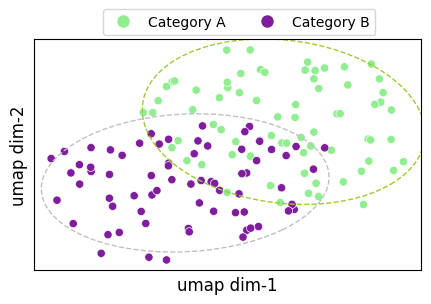

In [133]:
import umap
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# Configure and apply MDS
# Set n_components=2 to visualize in a 2D plot
# 'metric=True' (default) means we assume Euclidean distances
reducer = umap.UMAP(n_neighbors=10, min_dist=0.2, n_components=3)
orig_train_umap = reducer.fit_transform(train_set[0])

# 3. Plot the results
plt.figure(figsize=(5, 3))
plt.rcParams.update({'font.size': 12})
ax = sns.scatterplot(
    x=orig_train_umap[:, 0],
    y=orig_train_umap[:, 1],
    hue=labels_train_syn,
    palette=["#90ee90","#7e1e9c"],
)


cata_indices = np.where(labels_train_syn == 0)[0]
x_cata = orig_train_umap[:, 0][cata_indices]
y_cata = orig_train_umap[:, 1][cata_indices]
catb_indices = np.where(labels_train_syn == 1)[0]
x_catb = orig_train_umap[:, 0][catb_indices]
y_catb = orig_train_umap[:, 1][catb_indices]

draw_confidence_ellipse(x_cata, y_cata, ax, n_std=2, 
                        edgecolor='#9acd32', linestyle='--', label='1-sigma')
draw_confidence_ellipse(x_catb, y_catb, ax, n_std=2, 
                        edgecolor='silver', linestyle='--', label='2-sigma')

plt.xlabel("umap dim-1")
plt.ylabel("umap dim-2")
#ax.set_xlim(5, 10)
#ax.set_ylim(-3, 3)
ax.set_xticks([])
ax.set_yticks([])
#ax.set_xticklabels(['','',0,'',''])
#ax.set_yticklabels(['','',0,'',''])
plt.grid(False)

handles, _ = ax.get_legend_handles_labels()
# Add the legend with custom labels
patch_a = Line2D([0], [0], marker='o', color='white', markerfacecolor="#90ee90", markersize=10, label='Category A')
patch_b = Line2D([0], [0], marker='o', color='white', markerfacecolor="#7e1e9c", markersize=10, label='Category B')
ax.legend(handles=[patch_a, patch_b],bbox_to_anchor=(0.9, 1.16), ncol=2, fontsize=10)

plt.savefig("simulated_embeds_umap.pdf", format="pdf", bbox_inches='tight', dpi=300)
#plt.savefig("simulated_embeds_sae.pdf", format="pdf", bbox_inches='tight')
plt.show()



In [34]:
import umap

reducer = umap.UMAP(n_neighbors=10, min_dist=0.2, n_components=2)
orig_train_val_calib_emb_umap = reducer.fit_transform(embeddings_syn.detach().cpu().numpy())

len_train_data = embeddings_train_syn.shape[0]
len_val_data = embeddings_val_syn.shape[0]
len_calib_data = embeddings_calib_syn.shape[0]

orig_train_emb_umap = orig_train_val_calib_emb_umap[:len_train_data,:]
orig_train_labels = labels_syn[:len_train_data]
orig_train_val_emb_umap = orig_train_val_calib_emb_umap[:len_train_data+len_val_data,:]
orig_train_val_labels = labels_syn[:len_train_data+len_val_data]

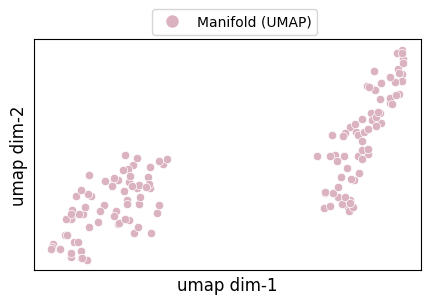

In [128]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


plt.figure(figsize=(5,3))
plt.rcParams.update({'font.size': 12})
ax = sns.scatterplot(
    x=orig_train_emb_umap[:, 0],
    y=orig_train_emb_umap[:, 1],
    c=["#dbb2bf"],
)

plt.xlabel("umap dim-1")
plt.ylabel("umap dim-2")
ax.set_xticks([])
ax.set_yticks([])

plt.grid(False)

handles, _ = ax.get_legend_handles_labels()
# Add the legend with custom labels
orange_patch = Line2D([0], [0], marker='o', color='white', markerfacecolor="#dbb2bf", markersize=10, label='Manifold (UMAP)')
ax.legend(handles=[orange_patch],bbox_to_anchor=(0.75, 1.16), fontsize=10)

#plt.savefig("simulated_embeds_umap.pdf", format="pdf", bbox_inches='tight', dpi=300)
plt.show()

In [37]:
embeddings_train_syn_umap = orig_train_val_calib_emb_umap[:len_train_data, :]
embeddings_val_syn_umap = orig_train_val_calib_emb_umap[len_train_data:len_train_data+len_val_data, :]
embeddings_calib_syn_umap = orig_train_val_calib_emb_umap[-len_calib_data:, :]

print(len(embeddings_calib_syn_umap))

40


In [38]:
# Find miscategorized points

mis_indices = []
#swap_clusters_syn = 1 - clusters_train_syn
swap_clusters_syn = clusters_train_syn
for i,c in enumerate(swap_clusters_syn):
    if c != labels_train_syn[i]:
        mis_indices.append(i)

print(f"Number of points miscategorized: {len(mis_indices)}")

Number of points miscategorized: 0


unique set sizes: [1 2]


/tmp/ipykernel_202/453654455.py:63: UserWarning: The palette list has more values (2) than needed (1), which may not be intended.
  sns.scatterplot(


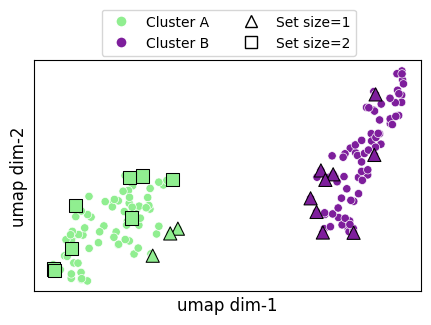

In [139]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


plt.figure(figsize=(5,3))
plt.rcParams.update({'font.size': 12})
ax = sns.scatterplot(
    x=embeddings_train_syn_umap[:, 0],
    y=embeddings_train_syn_umap[:, 1],
    hue=clusters_train_syn,
    palette=["#90ee90","#7e1e9c"],
)

marker_mapping = {0: "o",1: "o"}
sns.scatterplot(
    x=embeddings_val_syn_umap[:, 0],
    y=embeddings_val_syn_umap[:, 1],
    hue=clusters_val_syn,
    palette=["#90ee90","#7e1e9c"],
    markers=marker_mapping,
    ax=ax,
    style=labels_val_syn,
    #edgecolor="#2e2c2c",
)

# Highlight miscategorized points
for j in mis_indices:
    sns.scatterplot(
        x=[orig_train_emb_umap[j, 0]],
        y=[orig_train_emb_umap[j, 1]], 
        c=["#515450"],
        ax=ax,
        s=90
    )

avg_set_size = np.mean([len(s) for s in prediction_sets])
prediction_set_sizes = [len(s) for s in prediction_sets]
unique_sizes = np.sort(np.unique(prediction_set_sizes))

# Plot each data point    
print(f"unique set sizes: {unique_sizes}")
for set_idx, size in enumerate(unique_sizes):
    mask = (prediction_set_sizes == size)
    
    # Use different marker shapes based on the true label for context
    marker_map = {0: 'X', 1: '^', 2: 's'}

    # Ensure there are points to plot for the current size
    if np.sum(mask) == 0:
        continue
        
    # Determine the marker type for the points in this group
    # This assumes that the labels within a cluster are homogenous
    #current_labels = test_labels_2d[mask]
    current_labels = clusters_val_syn[mask]
    #marker_type = marker_map.get(np.sort(current_labels)[::-1][0], 'o') 
    marker_type = marker_map[size]
    
    # Plotting the points corresponding to the current set size
    sns.scatterplot(
        x=embeddings_val_syn_umap[mask, 0],
        y=embeddings_val_syn_umap[mask, 1], 
        hue=current_labels,
        palette=["#90ee90","#7e1e9c"],
        marker=marker_type,
        ax=ax,
        s=90,
        edgecolors='black'  # Highlight points with large sets
    )

plt.xlabel("umap dim-1")
plt.ylabel("umap dim-2")
ax.set_xticks([])
ax.set_yticks([])
#ax.set_xticks(range(-10,15,5))
#ax.set_yticks(range(-10,15,5))
#ax.set_xticklabels(['','',0,'',''])
#ax.set_yticklabels(['','',0,'',''])
handles, _ = ax.get_legend_handles_labels()
# Add the legend with custom labels
cata_patch = Line2D([0], [0], marker='o', color='white', markerfacecolor="#90ee90", markersize=8, label='Cluster A')
catb_patch = Line2D([0], [0], marker='o', color='white', markerfacecolor="#7e1e9c", markersize=8, label='Cluster B')
miscat_patch = Line2D([0], [0], marker='o', color='white', markerfacecolor="#515450", markersize=8, label='Miscategorized')
set_size0_patch = Line2D([0], [0], marker='X', color='white', markeredgecolor='black', markersize=8, label='Set size=0')
set_size1_patch = Line2D([0], [0], marker='^', color='white', markeredgecolor='black', markersize=8, label='Set size=1')
set_size2_patch = Line2D([0], [0], marker='s', color='white', markeredgecolor="black", markersize=8, label='Set size=2')

# Look at the set size to add this
#ax.legend(handles=[cata_patch, catb_patch,set_size0_patch,set_size1_patch,set_size2_patch], loc='upper right')
ax.legend(handles=[cata_patch, catb_patch,set_size1_patch,set_size2_patch], bbox_to_anchor=(0.85, 1.25), ncol=2, fontsize=10)

plt.grid(False)

plt.savefig("simulated_embeds_coverage_umap.pdf", format="pdf", bbox_inches='tight', dpi=300)
#plt.savefig("simulated_embeds_coverage_sae.pdf", format="pdf", bbox_inches='tight')
plt.show()

### Curated Data

#### MilvusDB containing the black-box encoding

In [ ]:
from pymilvus import MilvusClient, FieldSchema, CollectionSchema, DataType
from model.datasets import MilvusDataset

DB_NAME = 'word_sense_embeddings'
BATCH_SIZE = 64
SHUFFLE = False # Shuffle data every epoch
NUM_WORKERS = 0 # Use multi-process data loading (optional, set to 0 for single process)

COLLECTION_NAME = 'wordnet_human_values_sense_embeddings_qwen38b'
collection_a_dataset = MilvusDataset(
    db_name=DB_NAME,
    collection_name=COLLECTION_NAME,
    batch_size = BATCH_SIZE,
    output_fields = ["id", "sense_embedding", "is_human_value", "word"],
    items2exclude = words_valid + words_calib
)
collection_a_dataloader = DataLoader(
    collection_a_dataset,
    batch_size=None,
    shuffle=SHUFFLE,
    num_workers=NUM_WORKERS
)
COLLECTION_NAME = 'wordnet_non_values_sense_embeddings_qwen38b'
collection_b_dataset = MilvusDataset(
    db_name=DB_NAME,
    collection_name=COLLECTION_NAME,
    batch_size = BATCH_SIZE,
    output_fields = ["id", "sense_embedding", "is_human_value", "word"],
    items2exclude = words_valid + words_calib
)
collection_b_dataloader = DataLoader(
    collection_b_dataset,
    batch_size=None,
    shuffle=SHUFFLE,
    num_workers=NUM_WORKERS
)

#### Generate training and calibration sets

In [3]:
from model.datasets import setup_contrastive_training,fetch_subset,extract_from_dataloader

In [86]:
NUM_PAIRS=3000
BATCH_SIZE=64

contrastive_train_dataloader,train_labels,milvus_dataset = setup_contrastive_training(num_pairs_per_type=NUM_PAIRS, 
                                                                                      batch_size=BATCH_SIZE,
                                                                                      train_part=0.7,val_part=0.1)


Total entities: 1869
Number of train entities: 1301
Number of validation entities: 102
Number of calibration entities: 466
1869 = 1301 + 102 + 466 = 1869
Generated 6000 pairs (3000 similar) for training.


In [ ]:
## Validation data
validation_dataset_a_dataloader,validation_dataset_b_dataloader=fetch_subset(milvus_dataset, 'validation')
words_a_valid, embeddings_a_valid, labels_a_valid = extract_from_dataloader(validation_dataset_a_dataloader)
words_b_valid, embeddings_b_valid, labels_b_valid = extract_from_dataloader(validation_dataset_b_dataloader)

words_valid = words_a_valid + words_b_valid
embeddings_valid = torch.vstack((embeddings_a_valid, embeddings_b_valid))
labels_valid = labels_a_valid + labels_b_valid

print(f"Number of words in validation set: {len(words_valid)}")
print(f"Shape of embeddings in validation set: {embeddings_valid.shape}")
print(f"Number of labels in validation set: {len(labels_valid)}")

print(f"Sample item in word list: {words_valid[0]}")

In [ ]:
## Calibration data
calib_dataset_a_dataloader,calib_dataset_b_dataloader = fetch_subset(milvus_dataset, 'calibration')
words_a_calib, embeddings_a_calib, labels_a_calib = extract_from_dataloader(calib_dataset_a_dataloader)
words_b_calib, embeddings_b_calib, labels_b_calib = extract_from_dataloader(calib_dataset_b_dataloader)

words_calib = words_a_calib + words_b_calib
embeddings_calib = torch.vstack((embeddings_a_calib, embeddings_b_calib))
labels_calib = labels_a_calib + labels_b_calib

print(f"Number of words in calibration set: {len(words_calib)}")
print(f"Shape of embeddings in calibration set: {embeddings_calib.shape}")
print(f"Number of labels in calibration set: {len(labels_calib)}")

print(f"Sample item in word list: {words_calib[0]}")

In [3]:
## Optional: Save the generated data for future
"""
tensor_to_save = {
    "contrastive_train_dataloader" : contrastive_train_dataloader,
    "train_labels" : train_labels,
    "embeddings_valid" : embeddings_valid,
    "labels_valid" : labels_valid,
    "words_valid" : words_valid,
    "embeddings_calib" : embeddings_calib,
    "labels_calib" : labels_calib,
    "words_calib" : words_calib,
    "milvus_dataset" : milvus_dataset,
}

torch.save(tensor_to_save, 'data/data_3000_pairs.pt')
"""

## Optional: Load the saved data
"""
loaded_tensor = torch.load('data/data_3000_pairs.pt', weights_only=False)
contrastive_train_dataloader=loaded_tensor['contrastive_train_dataloader']
train_labels=loaded_tensor['train_labels']
embeddings_valid=loaded_tensor['embeddings_valid']
labels_valid=loaded_tensor['labels_valid']
words_valid=loaded_tensor['words_valid']
labels_valid=loaded_tensor['labels_valid']
words_valid=loaded_tensor['words_valid']
embeddings_calib=loaded_tensor['embeddings_calib']
labels_calib=loaded_tensor['labels_calib']
words_calib=loaded_tensor['words_calib']
milvus_dataset=loaded_tensor['milvus_dataset']
"""



#### Locate Schwartz values in the validation set

In [142]:
def find_words_in_list(words_list, lookup_list):
    words_found = []
    for position, x in enumerate(words_list):
        if x[1] in lookup_list:
            words_found.append({"list_index": position, "word" : x[1], 'id' : x[0]})
    return words_found


In [ ]:
# Locate Schwartz values again as new dataloader was used

schwartz_vals = ['self-direction', 'stimulation','hedonism','achievement','power','security','conformity','tradition','benevolence','universalism']
matches_valid = find_words_in_list(words_valid, schwartz_vals)

print(f"Number of matches in the words in validation set: {len(matches_valid)}")     # Validation set only contains Schwartz values with hv=true

schwartz_vals_indices_valid = []
schwartz_vals_found = []
for u in matches_valid:
    # power and conformity have multiple hv senses.
    if u['word'] in schwartz_vals_found:
        continue
    # make sure it's a hv
    if labels_valid[u["list_index"]] == 1:
        schwartz_vals_indices_valid.append(u['list_index'])
        schwartz_vals_found.append(u['word'])

print(f"Located Schwartz values: {schwartz_vals_found} Total: {len(schwartz_vals_found)}")
print(f"Located Schwartz values (validation set):\n{matches_valid}")


#### Train Contrastive Embedder

In [89]:
from model.training import train_autoencoder_prepared_data, train_contrastive_embeddings_transformer_prepared_data


In [ ]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
INPUT_DIM = 4096
EMBED_DIM = 256
BATCH_SIZE = 64
EPOCHS = 80
LEARNING_RATE = 1e-4
MARGIN = 0.7

emb_model = train_contrastive_embeddings_transformer_prepared_data(contrastive_train_loader=contrastive_train_dataloader, input_dim=INPUT_DIM, embedding_dim = EMBED_DIM, 
                                                     device = DEVICE, epochs=EPOCHS, learning_rate=LEARNING_RATE, margin=MARGIN)



#### Train Autoencoder

In [ ]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
INPUT_DIM = 4096
LATENT_DIM = EMBED_DIM
BATCH_SIZE = 64
EPOCHS = 4
LEARNING_RATE = 0.001

ae_model, train_dataloader = train_autoencoder_prepared_data(emb_model, milvus_dataset, input_dim=INPUT_DIM, latent_dim=LATENT_DIM, 
                                                             device = DEVICE, batch_size=BATCH_SIZE, epochs=EPOCHS, learning_rate=LEARNING_RATE)



#### Reduce Dimensionality

In [92]:
from model.models import ContrastiveEmbeddingsTransformer, EmbeddingsAutoencoderService, ContrastiveClusterLearner


## Transform data for clustering

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
cse_model = EmbeddingsAutoencoderService(autoencoder=ae_model, embed_transformer=emb_model, device=DEVICE)
ccl_model = ContrastiveClusterLearner(embed_transformer = cse_model, device=DEVICE)

embeddings_a, words_a, labels_a = ccl_model.transform_embeddings(collection_a_dataloader)
embeddings_b, words_b, labels_b = ccl_model.transform_embeddings(collection_b_dataloader)
embeddings = torch.vstack((embeddings_a, embeddings_b))
embeddings_labels = np.concatenate((labels_a.astype(int), labels_b.astype(int)), axis=0)

words_valid2 = [item[1] for item in words_valid]
train_valid_words = words_a + words_b + words_valid2

labels_train = embeddings_labels.tolist()
labels_train_valid = labels_train + labels_valid



In [93]:
embeddings_valid = cse_model.encode_transform(embeddings_valid)
print(f"Validation data size: {embeddings_valid.shape}")
embeddings_calib = cse_model.encode_transform(embeddings_calib)
print(f"Calibration data size: {embeddings_calib.shape}")

## Concat the embeddings sets for clustering
embeddings_train_calib = torch.vstack((embeddings, embeddings_calib))
embeddings_train_calib_valid = torch.vstack((embeddings_train_calib, embeddings_valid))


Validation data size: torch.Size([102, 256])
Calibration data size: torch.Size([466, 256])


#### Train Clustering Model

In [ ]:
import random

## To align labels, centroids must be initialized by randomly selected embeddings whose labels are 0 and 1
random_index_0 = len(labels_a) + random.randrange(len(labels_b))
random_index_1 = random.randrange(len(labels_a))
print(f"Randomly selected indices : {random_index_0}, {random_index_1}")

## Fit to training data
pred_clusters_train, train_centroids = ccl_model.cosine_kmeans_fit(embeddings,num_clusters=2,initial_indices=[random_index_0,random_index_1])
pred_clusters_train = pred_clusters_train.cpu() 

# Predict centers
pred_clusters_valid = ccl_model.predict_clusters(embeddings_valid.detach().cpu(), train_centroids.cpu())
pred_clusters_calib = ccl_model.predict_clusters(embeddings_calib.detach().cpu(), train_centroids.cpu())


pred_clusters_train_calib = np.concat((pred_clusters_train, pred_clusters_calib))
pred_clusters_train_calib_valid = np.concat((pred_clusters_train_calib, pred_clusters_valid))

print(f"Number of assigned cluster centroids during training: {len(pred_clusters_train)}")
print(f"Number of assigned validation cluster centroids: {len(pred_clusters_valid)}")



In [ ]:
from sklearn.metrics import adjusted_rand_score, accuracy_score, normalized_mutual_info_score, v_measure_score

accuracy_score(labels_valid,pred_clusters_valid)

#### Conformal Calibration

In [ ]:

## (1) Predict categories for calibration data
pred_labels_calib = ccl_model.predict_clusters(embeddings_calib.detach().cpu(), train_centroids.cpu())

# (2) Calculate Residuals (aka conformity score) using the calibration data for the predicted labels
calib_deltas = ccl_model.calculate_calibration_conformity_scores_loo(embeddings_calib, pred_labels_calib.detach().clone())

# (3) Compute per class quantile thresholds
q_hat = {}
CONFIDENCE = 0.9
gamma = 1 - CONFIDENCE # Significance level
    
for c, deltas in calib_deltas.items():
    if not deltas: continue
    # The quantile index is calculated as ceil((n+1) * (1-confidence)) - 1
    n = len(deltas)
    idx = int(np.ceil((n + 1) * gamma)) - 1
    
    # Sort and pick the quantile
    sorted_deltas = sorted(deltas)
    q_hat[c] = np.percentile(sorted_deltas, CONFIDENCE * 100)
    print(f"Predicted Class {c}: n={n}, Quantile q_hat = {q_hat[c]:.4f}")

# (4) Predict categories for validation data
pred_labels_valid = ccl_model.predict_clusters(embeddings_valid.detach().cpu(), train_centroids.cpu())

# (5) Conformity score for the validation data
all_test_scores = ccl_model.calculate_test_conformity_scores(embeddings_calib, pred_labels_calib.detach().clone(), embeddings_valid, pred_labels_valid.detach().clone())

# (6) Determine Prediction Sets for validation data
prediction_sets = []
coverage_count = 0
total_sets = len(labels_valid)
print(f"Total sets (len of validation data): {total_sets}")
unique_classes = np.unique(labels_valid)
class_coverage_total = {c: 0 for c in unique_classes}
coverage_gaps = {}

for i in range(total_sets):
    current_true_label = labels_valid[i]
    
    # Scores for the current test sample
    scores_i = all_test_scores[i] 
    
    # Find the set of possible labels (C(x))
    C_x = ccl_model.compute_prediction_set(scores_i, q_hat)
    prediction_sets.append(C_x)
    
    if current_true_label in C_x:
        coverage_count += 1
        class_coverage_total[current_true_label] += 1
    

In [ ]:
## Evaluation
coverage = coverage_count / total_sets
avg_set_size = np.mean([len(s) for s in prediction_sets])
prediction_set_sizes = [len(s) for s in prediction_sets]
    
print("\n--- Conformal Prediction Results ---")
print(f"Target Confidence (1-alpha): {CONFIDENCE:.2f}")
print(f"Empirical Coverage: {coverage:.4f}")
print(f"Average Prediction Set Size: {avg_set_size:.3f}")

# Example visualization of the first 5 predictions
print("\nExample Predictions (True Label | Prediction Set):")
for i in range(5):
    print(f"  {labels_valid[i]} | {prediction_sets[i]}")
    
print("\nThis method successfully uses the L2-normalized Euclidean distance (equivalent to cosine distance) to build the non-conformity scores.")


In [ ]:
precision_efficiency = 1 / avg_set_size if avg_set_size > 0 else 0
    
# 4. F1-Score (Harmonic mean of Efficiency and Coverage)
# F1 = 2 * (P * R) / (P + R)
recall_coverage = coverage 
if (precision_efficiency + recall_coverage) > 0:
    f1_score = 2 * (precision_efficiency * recall_coverage) / (precision_efficiency + recall_coverage)
else:
    f1_score = 0.0

print("\n--- Conformal Prediction Results ---")
print(f"Target Confidence (1-alpha): {CONFIDENCE:.2f}")

print("\n--- Summary Metrics (Adapted for Set Prediction) ---")
print(f"Empirical Coverage (Recall): {recall_coverage:.4f}")
print(f"Average Set Size (Inverse Precision): {avg_set_size:.3f}")
print(f"Set Efficiency (Precision): {precision_efficiency:.4f}")
print(f"F1-Score: {f1_score:.4f}")

In [ ]:
# Initialize structures for Conditional Coverage tracking
prediction_sets = []
all_coverage_count = 0
total_sets = len(labels_valid)
unique_classes = np.unique(labels_valid)
conditional_coverage_total = {c: 0 for c in unique_classes}
conditional_coverage_correct = {c: 0 for c in unique_classes}


for i in range(total_sets):
    current_true_label = labels_valid[i]
    scores_i = all_test_scores[i] 
    
    # Find the set of possible labels (C(x))
    C_x = ccl_model.compute_prediction_set(scores_i, q_hat)
    prediction_sets.append(C_x)
    
    # Update conditional coverage tracking
    conditional_coverage_total[current_true_label] += 1

    if current_true_label in C_x:
        all_coverage_count += 1 # Marginal Coverage
        conditional_coverage_correct[current_true_label] += 1

        
# --- 3.4. Evaluation ---

coverage = all_coverage_count / total_sets

set_sizes_0, set_sizes_1, set_sizes_2 = 0, 0, 0
set_sizes = {'0':set_sizes_0, '1':set_sizes_1, '2':set_sizes_2}
             
for s in prediction_sets:
    if len(s) == 0:
       set_sizes['0'] = set_sizes['0'] + 1
    elif len(s) == 1:
       set_sizes['1'] = set_sizes['1'] + 1
    if len(s) == 2:
       set_sizes['2'] = set_sizes['2'] + 1

total_set_size = sum(set_sizes.values())
print(set_sizes)
avg_set_size = np.mean([len(s) for s in prediction_sets])
coverage_gaps = {}

print("\n--- Conformal Prediction Results ---")
print(f"Target Confidence (1-alpha): {CONFIDENCE:.2f}")
print(f"Empirical Marginal Coverage: {coverage:.4f}")
print(f"Average Prediction Set Size: {avg_set_size:.3f}")

for k,v in set_sizes.items():
    proportion = int(v)/total_set_size
    print(f"Set size={k} Proportion={proportion:.3f}")

print("\n--- Empirical Conditional Coverage: High if either (1) SetSize=2 is larger (2) Model is more accurate for SetSize=1 predictions ---")
# This shows the actual coverage achieved for each specific class
for c in sorted(conditional_coverage_total.keys()):
    total = conditional_coverage_total[c]
    correct = conditional_coverage_correct[c]
    if total > 0:
        cond_cov = correct / total     # Matches the cc cov definition in the reference paper (Ding et al)
        print(f"  Class {c} Coverage (n={total}): {cond_cov:.4f}")
    else:
        print(f"  Class {c} Coverage (n=0): N/A (No test samples for this class)")

    gap = (cond_cov - CONFIDENCE) # Signed gap
    coverage_gaps[c] = {
        'class_conditional_coverage': f"{cond_cov:.3f}",
        'gap': f"{gap:.3f}",
        'absolute_gap': f"{abs(gap):.3f}"
    }

print("\n--- Class Conditional Coverage Gaps ---")  
total_cov_gap = 0
for c in sorted(coverage_gaps.keys()):
    cov_gap = coverage_gaps[c]
    print(cov_gap)
    print(f"Cluster {c}: Class Conditional={cov_gap['class_conditional_coverage']}, Gap={cov_gap['gap']}")
    total_cov_gap = total_cov_gap + float(cov_gap['absolute_gap'])


print("\n--- Avg Class Conditional Coverage Gap ---") 
avg_cov_gap = (100 * total_cov_gap)/(len(conditional_coverage_total.keys()))
print(f"{avg_cov_gap:.2f}%")
    

### Schwartz Values

In [167]:
### Schwartz values in the combined set
schwartz_vals = ['self-direction', 'stimulation','hedonism','achievement','power','security','conformity','tradition','benevolence','universalism']
schwartz_vals_indices_train_valid = []
matches_train_valid = []

# Filter the sublist that contains indices corres to words_valid
train_valid_words2 = train_valid_words[-len(words_valid):]
offset = len(train_valid_words) - len(train_valid_words2)

for i, word in enumerate(train_valid_words2):
    # skip the multiple occurence
    if word in matches_train_valid:
        continue
    if word in schwartz_vals:
        matches_train_valid.append(word)
        schwartz_vals_indices_train_valid.append(offset+i)

        
print(f"Located Schwartz values: {matches_train_valid} Total: {len(matches_train_valid)}")
print(f"Located Schwartz values (validation set):\n{schwartz_vals_indices_train_valid}")

Located Schwartz values: ['self-direction', 'stimulation', 'hedonism', 'achievement', 'power', 'security', 'tradition', 'benevolence', 'universalism', 'conformity'] Total: 10
Located Schwartz values (validation set):
[1625, 1626, 1627, 1628, 1629, 1630, 1631, 1632, 1633, 1634]


### Visualization

In [130]:
## T-SNE transform

from sklearn.manifold import TSNE

# Apply t-SNE for dimensionality reduction
len_train_data = embeddings.shape[0]
len_valid_data = embeddings_valid.shape[0]

embeddings_train_valid_tsne_2d = ccl_model.lean_manifold_tsne(embeddings_train_valid, perplexity=20)
embeddings_valid_tsne_2d = embeddings_train_valid_tsne_2d[len_train_data:, :]
embeddings_train_tsne_2d = embeddings_train_valid_tsne_2d[:len_train_data, :]


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from adjustText import adjust_text

plt.figure(figsize=(6,4))
plt.rcParams.update({'font.size': 12})
ax = sns.scatterplot(
    x=embeddings_train_tsne_2d[:, 0],
    y=embeddings_train_tsne_2d[:, 1],
    hue=clusters_train_valid,
    palette=["#8fcaca","#f8e3b8"],
)

# highlight first point for reference
sns.scatterplot(
    x=[embeddings_train_tsne_2d[0, 0].item()],
    y=[embeddings_train_tsne_2d[0, 1].item()],
    facecolors='#e04fbc',
    ax=ax
)

texts = []
for i in schwartz_vals_indices_train_valid:
    sns.scatterplot(
        x=[embeddings_train_valid_tsne_2d[i, 0].item()],
        y=[embeddings_train_valid_tsne_2d[i, 1].item()],
        #c="#f8e3b8",
        facecolor='none',
        edgecolors='red'
    )
    label = train_valid_words[i]
    texts.append(ax.annotate(label, xy=(embeddings_train_valid_tsne_2d[i,0], embeddings_train_valid_tsne_2d[i,1]), 
                              xytext=(embeddings_train_valid_tsne_2d[i,0], embeddings_train_valid_tsne_2d[i,1]),
                            fontsize=12))

# Automatically adjust the text positions to avoid overlap
adjust_text(texts, arrowprops=dict(arrowstyle='-', color='grey', lw=0.5))


plt.xlabel("umap dim-1")
plt.ylabel("umap dim-2")
ax.set_xticks([])
ax.set_yticks([])
handles, _ = ax.get_legend_handles_labels()
# Add the legend with custom labels
orange_patch = Line2D([0], [0], marker='o', color='white', markerfacecolor="#f8e3b8", label='Values')
green_patch = Line2D([0], [0], marker='o', color='white', markerfacecolor="#8fcaca", label='Non values')
ax.legend(handles=[orange_patch,green_patch],bbox_to_anchor=(0.8, 1.15), ncol=2, fontsize=12)


plt.grid(False)

#plt.savefig("bc_clustering_results_8k_128.pdf", format="pdf", dpi=300)

plt.show()

In [6]:
### All data combined

# Apply t-SNE for dimensionality reduction
embeddings_train_calib_valid_tsne_2d =  ccl_model.lean_manifold_tsne(embeddings_train_calib_valid, perplexity=20)
embeddings_calib_tsne_2d = embeddings_train_calib_valid_tsne_2d[len_train_data:len_train_data+len_calib_data].detach().cpu()
embeddings_valid_tsne_2d = embeddings_train_calib_valid_tsne_2d[-len_valid_data:].detach().cpu()



In [ ]:
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# 4. Plotting the Results
print("-" * 50)
print(f"Visualization showing Uncertainty (Set Size)")
print(f"Critical Quantile (q): 0:{q_hat[0]:.4f}, 1:{q_hat[1]:.4f}")
print(f"Max Set Size: {np.max(prediction_set_sizes)}")
print(f"Min Set Size: {np.min(prediction_set_sizes)}")

plt.figure(figsize=(6, 4))

#blue_patch = mpatches.Patch(color="#5c2306", label='New data')
#custom_colors = ["#F2F2F2","#F2F2F2","#F3F3F3"]
custom_colors = ["#ded3d8","#e3f7d7"]
custom_palette = sns.color_palette(custom_colors)

ax = sns.scatterplot(
    x=embeddings_train_calib_valid_tsne_2d[:, 0],
    y=embeddings_train_calib_valid_tsne_2d[:, 1], 
    hue=clusters_train_calib_valid,
    palette=custom_palette,
    alpha=0.8,
)

# Normalize set sizes to use them for coloring (e.g., 1, 2, 3)
unique_sizes = np.sort(np.unique(prediction_set_sizes))

# Plot each data point    
#custom_colors = ["#ae5a41", "#c3cb71"]
for set_idx, size in enumerate(unique_sizes):
    mask = (prediction_set_sizes == size)
    mask_true = []

    if size == 1:
        for i in range(0,len(mask)):
            if mask[i] == True:
                mask_true.append(i)
        print(mask_true)
    
    # Use different marker shapes based on the true label for context
    marker_map = {0: 'o', 1: '^', 2: 's'}

    # Ensure there are points to plot for the current size
    if np.sum(mask) == 0:
        continue
        
    # Determine the marker type for the points in this group
    # This assumes that the labels within a cluster are homogenous
    current_labels = clusters_labels_valid[mask].cpu()
    #marker_type = marker_map.get(np.sort(current_labels)[::-1][0], 'o') 
    marker_type = marker_map[set_idx]
    
    # Plotting the points corresponding to the current set size
    sns.scatterplot(
        x=embeddings_valid_tsne_2d[mask, 0],
        y=embeddings_valid_tsne_2d[mask, 1], 
        hue=clusters_relab_valid[mask],
        palette=custom_palette,
        marker=marker_type,
        #label=f'Set Size: {size}',
        ax=ax,
        edgecolors='slategray'  # Highlight points with large sets
    )


### Few words
texts = []
locs = [110, 111, 112, 113, 114, 115, 116,190,191,193,194]

for i in locs:
    sns.scatterplot(
        x=[embeddings_valid_tsne_2d[i, 0].item()],
        y=[embeddings_valid_tsne_2d[i, 1].item()],
        #c="#f8e3b8",
        facecolor='none',
        edgecolors=None
    )
    label = words_valid2[i]
    texts.append(ax.annotate(label, xy=(embeddings_valid_tsne_2d[i,0], embeddings_valid_tsne_2d[i,1]), 
                              xytext=(embeddings_valid_tsne_2d[i,0], embeddings_valid_tsne_2d[i,1]),
                            fontsize=12))

# Automatically adjust the text positions to avoid overlap
adjust_text(texts, arrowprops=dict(arrowstyle='-', color='grey', lw=0.5))

set_size0_patch = Line2D([0], [0], marker='o', color='white', markeredgecolor='slategray', markersize=10, label='Set size=0')
set_size1_patch = Line2D([0], [0], marker='^', color='white', markeredgecolor='slategray', markersize=10, label='Set size=1')
set_size2_patch = Line2D([0], [0], marker='s', color='white', markeredgecolor='slategray', markersize=10, label='Set size=2')

nonval_patch = Line2D([0], [0], marker='o', color='white', markerfacecolor='#ded3d8', markersize=10, label='Non values')
humval_patch = Line2D([0], [0], marker='o', color='white', markerfacecolor='#e3f7d7', markersize=10, label='Values')

ax.set_xticks([])
ax.set_yticks([])
plt.title("")
plt.xlabel("umap dim-1")
plt.ylabel("umap dim-2")

handles, _ = ax.get_legend_handles_labels()
# Add the legend with custom labels
ax.legend(handles=[set_size0_patch,humval_patch,set_size1_patch,nonval_patch,set_size2_patch,], title="", 
          bbox_to_anchor=(0.95, 1.2), ncol=3, fontsize=10)

#plt.savefig("figures/bc_conformal_8k_128.pdf", format="pdf", bbox_inches='tight', dpi=300)
plt.show()

In [ ]:
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# 4. Plotting the Results
print("-" * 50)
print(f"Visualization showing Uncertainty (Set Size)")
print(f"Critical Quantile (q): 0:{q_hat[0]:.4f}, 1:{q_hat[1]:.4f}")
print(f"Max Set Size: {np.max(prediction_set_sizes)}")
print(f"Min Set Size: {np.min(prediction_set_sizes)}")

plt.figure(figsize=(4.5, 3))

custom_colors = ["#ded3d8","#e3f7d7"]
custom_palette = sns.color_palette(custom_colors)

ax = sns.scatterplot(
    x=embeddings_train_calib_valid_tsne_2d[:, 0],
    y=embeddings_train_calib_valid_tsne_2d[:, 1], 
    hue=clusters_train_calib_valid,
    palette=custom_palette,
    alpha=0.8,
)

unique_sizes = np.sort(np.unique(prediction_set_sizes))

# Plot each data point    
#custom_colors = ["#ae5a41", "#c3cb71"]
for set_idx, size in enumerate(unique_sizes):
    mask = (prediction_set_sizes == size)
    
    # Use different marker shapes based on the true label for context
    marker_map = {0: 'o', 1: '^', 2: 's'}

    # Ensure there are points to plot for the current size
    if np.sum(mask) == 0:
        continue
        
    # Determine the marker type for the points in this group
    # This assumes that the labels within a cluster are homogenous
    #current_labels = test_labels_2d[mask]
    current_labels = clusters_labels_valid[mask].cpu()
    marker_type = marker_map[set_idx]
    
    # Plotting the points corresponding to the current set size
    sns.scatterplot(
        x=embeddings_valid_tsne_2d[mask, 0],
        y=embeddings_valid_tsne_2d[mask, 1], 
        hue=clusters_relab_valid[mask],
        palette=custom_palette,
        marker=marker_type,
        #label=f'Set Size: {size}',
        ax=ax,
        edgecolors='slategray'  # Highlight points with large sets
    )

words_to_plot = ['security','trust','reliability']
texts = []
label = 'security'
i = 120
texts.append(ax.annotate(label, xy=(embeddings_train_valid_tsne_2d[i,0], embeddings_train_valid_tsne_2d[i,1]), 
                              xytext=(embeddings_train_valid_tsne_2d[i,0], embeddings_train_valid_tsne_2d[i,1]),color='blue'))
label = 'trust'
i = 201
texts.append(ax.annotate(label, xy=(embeddings_train_valid_tsne_2d[i,0], embeddings_train_valid_tsne_2d[i,1]), 
                              xytext=(embeddings_train_valid_tsne_2d[i,0], embeddings_train_valid_tsne_2d[i,1]),color='blue'))
label = 'reliability'
i = 351
texts.append(ax.annotate(label, xy=(embeddings_train_valid_tsne_2d[i,0], embeddings_train_valid_tsne_2d[i,1]), 
                              xytext=(embeddings_train_valid_tsne_2d[i,0], embeddings_train_valid_tsne_2d[i,1]),color='blue'))


# Automatically adjust the text positions to avoid overlap
adjust_text(texts, arrowprops=dict(arrowstyle='-', color='grey', lw=0.5))

set_size0_patch = Line2D([0], [0], marker='o', color='white', markeredgecolor='slategray', markersize=10, label='Set size=0')
set_size1_patch = Line2D([0], [0], marker='^', color='white', markeredgecolor='slategray', markersize=10, label='Set size=1')
set_size2_patch = Line2D([0], [0], marker='s', color='white', markeredgecolor='slategray', markersize=10, label='Set size=2')

nonval_patch = Line2D([0], [0], marker='o', color='white', markerfacecolor='#ded3d8', markersize=10, label='Non values')
humval_patch = Line2D([0], [0], marker='o', color='white', markerfacecolor='#e3f7d7', markersize=10, label='Values')

plt.title("")
plt.xlabel("")
plt.ylabel("")
ax.set_yticks([0.0])
ax.set_xticks([0.0])
handles, _ = ax.get_legend_handles_labels()
# Add the legend with custom labels
ax.legend(handles=[set_size0_patch,set_size1_patch,set_size2_patch, humval_patch,nonval_patch], title="", 
          bbox_to_anchor=(1.0, 0.5), ncol=1, fontsize=10)

#plt.savefig("figures/teaser_conformal.pdf", format="pdf", bbox_inches='tight', dpi=300)
plt.show()

## Unseen Data

In [112]:
import itertools

DB_NAME = 'word_sense_embeddings'
BATCH_SIZE = 256
SHUFFLE = False # Shuffle data every epoch
NUM_WORKERS = 0 
COLLECTION_NAME = 'blockchain_sense_in_sentences_embeddings_qwen38b'
new_sentences_dataset = MilvusDataset(
    db_name=DB_NAME,
    collection_name=COLLECTION_NAME,
    batch_size = BATCH_SIZE,
    output_fields = ["id", "sense_embedding", "word"]
)
new_sentences_dataloader = DataLoader(
    new_sentences_dataset,
    batch_size=None,
    shuffle=SHUFFLE,
    num_workers=NUM_WORKERS
)
N = 50
# Use islice to create a new iterator that stops after N items (or N batches,
# depending on your interpretation of 'items' and the batch size)
sliced_loader = itertools.islice(new_sentences_dataloader, N)

embeddings_new, words_new, new_labels = ccl_model.transform_embeddings(sliced_loader)


In [124]:
clusters_new_data = ccl_model.predict_clusters(embeddings_new, train_centroids)

len_train_data = embeddings.shape[0]
len_calib_data = embeddings_calib.shape[0]
len_new_data = embeddings_new.shape[0]

pred_labels_new = clusters_new_data.detach().cpu()
clusters_train_calib_valid_new = np.concat((pred_clusters_train_calib_valid, pred_labels_new))
embeddings_train_calib_valid_new = torch.vstack((embeddings_train_calib_valid,embeddings_new))


### Calibrate new data

In [ ]:
scores_new = ccl_model.calculate_test_conformity_scores(embeddings_calib, pred_labels_calib.detach().clone(), embeddings_new, pred_labels_new.detach().clone())

# Initialize structures for Conditional Coverage tracking
prediction_sets_new = []
coverage_count_new = 0

# For new data, we don't know the labels. Assign the predicted label.

pred_labels_new_np = pred_labels_new.numpy()
total_sets_new = len(pred_labels_new_np)
unique_classes_new = np.unique(pred_labels_new_np)
conditional_coverage_total_new = {c: 0 for c in unique_classes_new}
conditional_coverage_correct_new = {c: 0 for c in unique_classes_new}


for i in range(total_sets_new):
    current_true_label = pred_labels_new_np[i]   # Assign the predicted label.
    scores_i = scores_new[i] 
    
    # Find the set of possible labels (C(x))
    C_x = ccl_model.compute_prediction_set(scores_i, q_hat)
    prediction_sets_new.append(C_x)
    
    # Update conditional coverage tracking
    coverage_count_new += 1
    conditional_coverage_total_new[current_true_label] += 1

    if current_true_label in C_x:
        coverage_count += 1 # Marginal Coverage
        conditional_coverage_correct_new[current_true_label] += 1
        
# --- 3.4. Evaluation ---

coverage_new = coverage_count_new / total_sets_new
avg_set_size_new = np.mean([len(s) for s in prediction_sets_new])
set_sizes = [len(s) for s in prediction_sets_new]

print("\n--- Conformal Prediction Results ---")
print(f"Target Confidence (1-alpha): {CONFIDENCE:.2f}")
print(f"Empirical Marginal Coverage: {coverage_new:.4f}")
print(f"Average Prediction Set Size: {avg_set_size_new:.3f}")

counts = {}
for item in set_sizes:
    counts[item] = counts.get(item, 0) + 1

print(f"Prediction Set Sizes Per Class: {counts}")
print(f"Proportion of Set Size 1: {counts[1]/sum(counts.values())}")
        


print("\n--- Empirical Conditional Coverage ---")
# This shows the actual coverage achieved for each specific class
for c in sorted(conditional_coverage_total_new.keys()):
    total = conditional_coverage_total_new[c]
    correct = conditional_coverage_correct_new[c]
    if total > 0:
        cond_cov = correct / total
        print(f"  Class {c} Coverage (n={total}): {cond_cov:.4f}")
    else:
        print(f"  Class {c} Coverage (n=0): N/A (No test samples for this class)")


### Filter the human values based on prediction set size

In [134]:
## Given the list of new words "words_new", we want to filter the words that represent human values
## and whose conformal predictive set-size are 1.

## (1) Identify predictions whose set sizes are 1
## (2) Filter human values from the predictions with set size = 1
assert len(set_sizes) == len(pred_labels_new_np)

indices_hv_pred_set_size_one = []
for i, x in enumerate(set_sizes):
    if x == 1 and pred_labels_new_np[i] == 1:
        indices_hv_pred_set_size_one.append(i)



In [9]:
for idx in indices_hv_pred_set_size_one:
    print(words_new[idx])

In [807]:
### top most common elements
from collections import OrderedDict, Counter

def most_common(word_list, k):
    word_counter = {}
    for word in word_list:
        if str(word) in word_counter:
            word_counter[str(word)] += 1
        else:
            word_counter[str(word)] = 1
    comm_words = sorted(word_counter, key = word_counter.get, reverse = True) 
    return comm_words[:k]


#### Silhouette Scores

In [ ]:
## Before new data

from sklearn.metrics import silhouette_score, silhouette_samples

sample_silhouette_values = silhouette_samples(embeddings_train_calib_valid.cpu().numpy(), clusters_train_calib_valid)
unique_labels = np.unique(clusters_train_calib_valid)
cluster_silhouette_scores = {}

for label in unique_labels:
    # Get the silhouette values for samples in the current cluster
    cluster_samples_silhouette_values = sample_silhouette_values[clusters_train_calib_valid == label]
    
    # Calculate the mean silhouette score for this cluster
    mean_cluster_silhouette_score = np.mean(cluster_samples_silhouette_values)
    cluster_silhouette_scores[label] = mean_cluster_silhouette_score

print("Silhouette scores per cluster:")
for label, score in cluster_silhouette_scores.items():
    print(f"Cluster {label}: {score:.4f}")

In [228]:
# Calculate the mean silhouette score for each cluster

from sklearn.metrics import silhouette_score, silhouette_samples

sample_silhouette_values = silhouette_samples(embeddings_train_calib_valid_new.cpu().numpy(), clusters_train_calib_valid_new)
unique_labels = np.unique(clusters_train_calib_valid_new)
cluster_silhouette_scores = {}

for label in unique_labels:
    # Get the silhouette values for samples in the current cluster
    cluster_samples_silhouette_values = sample_silhouette_values[clusters_train_calib_valid_new == label]
    
    # Calculate the mean silhouette score for this cluster
    mean_cluster_silhouette_score = np.mean(cluster_samples_silhouette_values)
    cluster_silhouette_scores[label] = mean_cluster_silhouette_score

print("Silhouette scores per cluster:")
for label, score in cluster_silhouette_scores.items():
    print(f"Cluster {label}: {score:.4f}")

Silhouette scores per cluster:
Cluster 0: 0.6008
Cluster 1: 0.4101
